# Klasifikasi Tutupan Lahan Multikelas Jawa Timur menggunakan Sentinel-2A

Notebook ini mengembangkan tugas sebelumnya menjadi enam kelas berdasarkan shapefile yang diberikan: **sawah, bangunan, mangrove, lahan hijau, perairan terbuka/laut, dan danau**.

| Kelas | Jumlah sampel awal |
|---|---:|
| Sawah | 50 |
| Bangunan | 50 |
| Mangrove | 50 |
| Lahan hijau | 50 |
| Perairan terbuka (laut) | 60 |
| Danau | 31 |
| **Total** | **291** |

Jumlah ini adalah geometri sampel awal. Sampel yang berhasil diekstrak dari raster bisa lebih sedikit karena NoData atau geometri di luar cakupan citra.


## 1. Import library dan koleksi sampel

Setiap shapefile diberi label kelas lalu digabungkan. File `.shp`, `.shx`, `.dbf`, dan `.prj` harus tetap berada dalam folder yang sama.

In [11]:
from IPython.display import display
from pathlib import Path
import geopandas as gpd
import pandas as pd
import os

sample_files = {
    "sawah": Path("Sampel Sawah/input.shp"),
    "bangunan": Path("Sampel Non-sawah/input.shp"),
    "mangrove": Path("mangrove/input.shp"),
    "lahan_hijau": Path("lahan hijau/input.shp"),
    "perairan_terbuka": Path("laut_lepas/input.shp"),
    "danau": Path("Danau/input.shp"),
}

def resolve_path(p: Path) -> Path:
    if p.exists():
        return p
    for prefix in [Path("materi"), Path("materi/materi"), Path("materi/sampel"), Path("."), Path(".."), Path("../materi")]:
        cand = prefix / p
        if cand.exists():
            return cand
        cand_lower = prefix / p.parent.name.lower() / p.name
        if cand_lower.exists():
            return cand_lower
    return p

frames = []
for label, path in sample_files.items():
    real_path = resolve_path(path)
    if not real_path.exists():
        raise FileNotFoundError(f"Shapefile tidak ditemukan: {path}")

    part = gpd.read_file(real_path)
    part["label"] = label
    frames.append(part)

# Samakan CRS semua data dengan CRS data pertama
target_crs = frames[0].crs
if target_crs is None:
    raise ValueError("CRS shapefile pertama tidak ditemukan.")

for i in range(len(frames)):
    if frames[i].crs is None:
        raise ValueError(f"CRS tidak ditemukan untuk kelas {list(sample_files.keys())[i]}")
    frames[i] = frames[i].to_crs(target_crs)

# Gabungkan seluruh sampel
sampel = gpd.GeoDataFrame(
    pd.concat(frames, ignore_index=True),
    geometry="geometry",
    crs=target_crs
)
sampel["sample_id"] = range(1, len(sampel) + 1)

print("Total sampel:", len(sampel))
print("\nJumlah sampel per kelas:")
display(sampel["label"].value_counts().rename_axis("kelas").to_frame("jumlah"))


Total sampel: 314

Jumlah sampel per kelas:


,jumlah
kelas,
sawah,60
bangunan,60
mangrove,50
lahan_hijau,50
danau,50
perairan_terbuka,44


## 2. Data understanding dan tujuan analisis

Tujuan analisis adalah memetakan perkiraan tutupan lahan berdasarkan karakteristik spektral citra satelit. Informasi ini dapat mendukung pemantauan pertanian, kawasan terbangun, vegetasi, mangrove, dan badan air. Hasil klasifikasi bukan pengganti penetapan resmi penggunaan lahan atau kebijakan tata ruang; hasil perlu divalidasi dengan data lapangan dan dokumen resmi.

## 3. Band Sentinel-2A dan fitur

- **B02 – Blue (biru), 10 m:** informasi pantulan spektrum biru.
- **B03 – Green (hijau), 10 m:** pantulan spektrum hijau; digunakan dalam NDWI versi Green-NIR.
- **B04 – Red (merah), 10 m:** pantulan merah; klorofil umumnya menyerap spektrum merah.
- **B08 – Near Infrared/NIR, 10 m:** respons vegetasi kuat; digunakan pada NDVI dan NDWI.
- **B11 – Short-Wave Infrared/SWIR, 20 m:** membantu membedakan kandungan air dan karakteristik permukaan. Resolusi akhirnya bergantung pada resampling proses.
- **NDVI:** `(B08 - B04) / (B08 + B04)`; indikator kehijauan/vegetasi.
- **NDWI (Green-NIR):** `(B03 - B08) / (B03 + B08)`; indikator terkait air/kelembapan.

B02–B11 merupakan nilai reflektansi dari citra, bukan hasil rumus turunan. NDVI/NDWI memakai epsilon pada penyebut untuk menghindari pembagian nol. NDWI memiliki beberapa varian; penelitian ini menggunakan Green dan NIR.


## 4. Menentukan wilayah sampel

Sampel diberikan pada beberapa lokasi di Jawa Timur. Bounding box gabungan berpotensi luas, sehingga proses pengunduhan citra dapat berat. Jika terlalu besar, lakukan pemrosesan per kelompok wilayah/AOI.

In [12]:
sampel_wgs84=sampel.to_crs("EPSG:4326")
minx,miny,maxx,maxy=sampel_wgs84.total_bounds
spatial_extent={"west":float(minx),"south":float(miny),"east":float(maxx),"north":float(maxy)}
print("Batas wilayah gabungan:",spatial_extent)


Batas wilayah gabungan: {'west': 109.5765557, 'south': -10.366915103472028, 'east': 115.301785, 'north': -5.7385827}


## 5. Mengambil citra Sentinel-2A Level-2A melalui OpenEO

Langkah ini memerlukan internet dan autentikasi Copernicus Data Space. Periode citra dapat diubah sesuai tanggal sampel dan kebutuhan analisis.

In [13]:
import os
from IPython.display import display

# Cek apakah raster sudah tersedia secara lokal (baik dari root maupun dari folder materi)
candidates = ["materi/Sentinel2_multikelas.tif", "Sentinel2_multikelas.tif", "../materi/Sentinel2_multikelas.tif"]
raster_path = None
for c in candidates:
    if os.path.exists(c):
        raster_path = c
        break

if raster_path:
    print("Raster Sentinel-2 multikelas sudah tersedia secara lokal:", raster_path)
else:
    print("Mencoba menghubungkan ke OpenEO Copernicus Data Space...")
    try:
        import openeo
        conn = openeo.connect("https://openeo.dataspace.copernicus.eu")
        conn.authenticate_oidc()
        datacube = conn.load_collection(
            "SENTINEL2_L2A",
            spatial_extent=spatial_extent,
            temporal_extent=["2025-08-31", "2026-08-31"],
            bands=["B02", "B03", "B04", "B08", "B11"]
        )
        composite = datacube.reduce_dimension(dimension="t", reducer="median")
        raster_path = "materi/Sentinel2_multikelas.tif"
        composite.download(raster_path, format="GTiff")
        print("Raster disimpan:", raster_path)
    except Exception as e:
        print(f"Catatan OpenEO: {e}")
        raster_path = "Sentinel2_multikelas.tif"


Raster Sentinel-2 multikelas sudah tersedia secara lokal: Sentinel2_multikelas.tif


## 6. Ekstraksi nilai band untuk setiap sampel

Nilai rata-rata piksel di dalam setiap geometri menjadi fitur sampel. Sampel yang tidak beririsan dengan raster atau tidak mempunyai piksel valid akan dilewati.

In [14]:
import rasterio
from rasterio.mask import mask
import numpy as np
import os
from IPython.display import display

target_raster = "Sentinel2_multikelas.tif" if os.path.exists("Sentinel2_multikelas.tif") else "materi/Sentinel2_multikelas.tif"
for alt in ["materi/Sentinel2_multikelas.tif", "Sentinel2_multikelas.tif", "../Sentinel2_multikelas.tif"]:
    if os.path.exists(alt):
        target_raster = alt
        break

hasil = []
with rasterio.open(target_raster) as src:
    sampel_raster = sampel.to_crs(src.crs)
    band_names = ["B02", "B03", "B04", "B08", "B11"]
    for _, row in sampel_raster.iterrows():
        try:
            arr, _ = mask(src, [row.geometry], crop=True, filled=False, all_touched=True)
            item = {"sample_id": row["sample_id"], "label": row["label"]}
            for i, name in enumerate(band_names[:src.count]):
                vals = np.ma.asarray(arr[i]).compressed()
                if src.nodata is not None:
                    vals = vals[vals != src.nodata]
                vals = vals[np.isfinite(vals)]
                item[name] = float(np.mean(vals)) if len(vals) else np.nan
            hasil.append(item)
        except Exception:
            continue

df = pd.DataFrame(hasil)
print("Sampel berhasil diekstrak:", len(df))
display(df.groupby("label").size().rename("jumlah_terekstrak").to_frame())
display(df.head())


Sampel berhasil diekstrak: 314


,jumlah_terekstrak
label,
bangunan,60
danau,50
lahan_hijau,50
mangrove,50
perairan_terbuka,44
sawah,60


,sample_id,label,B02,B03,B04,B08,B11
0,1,sawah,1265.0,1320.0,1260.0,1885.0,1370.0
1,2,sawah,1280.0,1390.0,1270.0,2520.0,1490.0
2,3,sawah,1280.0,1390.0,1270.0,2520.0,1490.0
3,4,sawah,1250.0,1250.0,1250.0,1250.0,1250.0
4,5,sawah,1250.0,1250.0,1250.0,1250.0,1250.0


## 7. Menghitung indeks dan membersihkan data

Fitur akhir berjumlah tujuh: lima band spektral dan dua indeks turunan. Baris dengan fitur kosong atau tak hingga dihapus sebelum pelatihan.

In [15]:
eps=1e-10
df["NDVI"]=(df["B08"]-df["B04"])/(df["B08"]+df["B04"]+eps)
df["NDWI"]=(df["B03"]-df["B08"])/(df["B03"]+df["B08"]+eps)
fitur=["B02","B03","B04","B08","B11","NDVI","NDWI"]
df=df.replace([np.inf,-np.inf],np.nan).dropna(subset=fitur+["label"])
print("Jumlah data bersih:",len(df))
print("Jumlah kelas:",df["label"].nunique())
display(df.groupby("label").size().rename("jumlah").to_frame())
display(df.groupby("label")[fitur].mean().round(4))


Jumlah data bersih: 314
Jumlah kelas: 6


,jumlah
label,
bangunan,60
danau,50
lahan_hijau,50
mangrove,50
perairan_terbuka,44
sawah,60


,B02,B03,B04,B08,B11,NDVI,NDWI
label,,,,,,,
bangunan,1251.5000,1257.0000,1251.0000,1313.5000,1262.0000,0.0176,-0.0155
danau,1270.5361,1257.7010,1220.4794,1188.3917,1181.9742,-0.0156,0.0309
lahan_hijau,1250.0000,1250.0000,1250.0000,1250.0000,1250.0000,0.0000,0.0000
mangrove,1229.8283,1251.5517,1208.1050,1543.2650,1271.7233,0.0935,-0.0775
perairan_terbuka,1643.7869,1023.5725,423.0475,186.7754,147.3967,-0.3880,0.6915
sawah,1251.7500,1258.1667,1251.1667,1324.0833,1264.0000,0.0198,-0.0174


## 8. Training dan testing 80:20

Pembagian menggunakan `stratify=y` agar proporsi kelas dipertahankan. Jumlah training/testing aktual dicetak setelah ekstraksi fitur, bukan ditetapkan dari jumlah sampel awal.

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier,ExtraTreesClassifier,HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,f1_score,classification_report,confusion_matrix,ConfusionMatrixDisplay

X=df[fitur]
y=df["label"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Jumlah kelas:",y.nunique())
print("Total data bersih:",len(df))
print("Data training (80%):",len(X_train))
print("Data testing (20%):",len(X_test))


Jumlah kelas: 6
Total data bersih: 314
Data training (80%): 251
Data testing (20%): 63


## 9. Membandingkan beberapa model

Model dibandingkan dengan accuracy dan macro-F1. Macro-F1 penting karena jumlah sampel tiap kelas tidak sepenuhnya seimbang. Model dengan accuracy paling tinggi pada testing dipilih sementara; untuk klaim yang kuat perlu validasi spasial dan sampel independen.

In [17]:
models = {
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    "SVM RBF": make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced")),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=42)
}
rows = []
for name, estimator in models.items():
    estimator.fit(X_train, y_train)
    pred = estimator.predict(X_test)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro")
    })
comparison = pd.DataFrame(rows).sort_values(["Accuracy", "Macro F1"], ascending=False).reset_index(drop=True)
display(comparison)
best_name = comparison.iloc[0]["Model"]
best_model = models[best_name]
y_pred = best_model.predict(X_test)
print("Model terbaik pada percobaan ini:", best_name)


,Model,Accuracy,Macro F1
0,Random Forest,0.412698,0.400556
1,Extra Trees,0.412698,0.400556
2,SVM RBF,0.412698,0.400556
3,HistGradientBoosting,0.412698,0.397307


Model terbaik pada percobaan ini: Random Forest


## 10. Evaluasi model terbaik

Periksa laporan per kelas dan confusion matrix, bukan hanya accuracy. Jika ada kelas yang memiliki recall rendah, perlu tambahan sampel atau peninjauan kualitas label.

Accuracy: 0.4126984126984127
Macro F1: 0.4005562338895672
                  precision    recall  f1-score   support

        bangunan       0.00      0.00      0.00        12
           danau       1.00      0.40      0.57        10
     lahan_hijau       0.23      1.00      0.37        10
        mangrove       1.00      0.30      0.46        10
perairan_terbuka       1.00      1.00      1.00         9
           sawah       0.00      0.00      0.00        12

        accuracy                           0.41        63
       macro avg       0.54      0.45      0.40        63
    weighted avg       0.50      0.41      0.37        63



,Prediksi bangunan,Prediksi danau,Prediksi lahan_hijau,Prediksi mangrove,Prediksi perairan_terbuka,Prediksi sawah
Aktual bangunan,0,0,10,0,0,2
Aktual danau,0,4,6,0,0,0
Aktual lahan_hijau,0,0,10,0,0,0
Aktual mangrove,0,0,7,3,0,0
Aktual perairan_terbuka,0,0,0,0,9,0
Aktual sawah,1,0,11,0,0,0


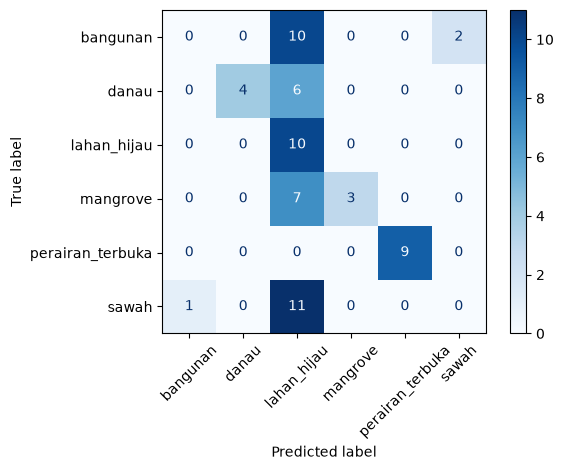

In [18]:
import matplotlib.pyplot as plt

labels = sorted(y.unique())
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro F1:", f1_score(y_test, y_pred, average="macro"))
print(classification_report(y_test, y_pred, labels=labels, zero_division=0))
cm = confusion_matrix(y_test, y_pred, labels=labels)
display(pd.DataFrame(cm, index=["Aktual " + x for x in labels], columns=["Prediksi " + x for x in labels]))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(xticks_rotation=45, cmap="Blues")
plt.tight_layout()
plt.show()


## 11. Menyimpan dataset, model, dan hasil evaluasi

File ini dapat digunakan kembali oleh aplikasi Streamlit. Hasil akurasi akan bergantung pada data citra yang benar-benar berhasil diunduh dan diekstrak.

In [19]:
import joblib
import os

os.makedirs("hasil", exist_ok=True)
df.to_csv("hasil/dataset_fitur_multikelas.csv", index=False)
joblib.dump({"model": best_model, "features": fitur, "classes": list(best_model.classes_)}, "hasil/model_klasifikasi.joblib")
comparison.to_csv("hasil/perbandingan_model.csv", index=False)
print("Tersimpan: dataset_fitur_multikelas.csv, model_klasifikasi.joblib, perbandingan_model.csv")


Tersimpan: dataset_fitur_multikelas.csv, model_klasifikasi.joblib, perbandingan_model.csv


## 12. Peta sampel dengan Folium dan Google Satellite

Peta berikut menampilkan sampel berlabel pada basemap satelit. Ini merupakan peta lokasi sampel, bukan peta hasil prediksi seluruh piksel. Overlay hasil klasifikasi raster dapat ditambahkan setelah raster prediksi penuh dibuat dan divalidasi.

In [20]:
import folium
import os

sampel_map = sampel.to_crs("EPSG:4326")
minx, miny, maxx, maxy = sampel_map.total_bounds
center_y, center_x = (miny + maxy) / 2, (minx + maxx) / 2
m = folium.Map(location=[center_y, center_x], zoom_start=8, tiles=None)
folium.TileLayer(tiles="https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}", attr="Google Satellite", name="Google Satellite", overlay=False, control=True).add_to(m)
colors = {"sawah": "#2ca25f", "bangunan": "#d73027", "mangrove": "#006837", "lahan_hijau": "#91cf60", "perairan_terbuka": "#2c7fb8", "danau": "#225ea8"}
for _, row in sampel_map.iterrows():
    color = colors.get(row["label"], "#555555")
    folium.GeoJson(row.geometry.__geo_interface__, style_function=lambda feat, c=color: {"color": c, "fillColor": c, "weight": 2, "fillOpacity": 0.35}, tooltip=f"Kelas: {row['label']} | ID: {row['sample_id']}").add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
os.makedirs("hasil", exist_ok=True)
m.save("hasil/peta_sampel_multikelas.html")
m


## 13. Acuan klasifikasi lahan dan kebijakan di Indonesia

Kelas dalam eksperimen ini merupakan label operasional dari sampel yang diberikan. Untuk pelaporan resmi, jelaskan bahwa kategori tidak otomatis identik dengan kelas pada legenda nasional. Cocokkan definisi dan batasnya dengan sumber yang relevan, misalnya peta penutup lahan KLHK, Peta Rupabumi Indonesia (RBI) dari BIG, serta RTRW/RDTR pemerintah daerah yang berlaku. Catat tahun, skala, definisi kelas, dan sumber data yang benar-benar digunakan.

## Batasan eksperimen

- Sampel kelas tidak seimbang (danau 31; perairan terbuka 60; kelas lain 50).
- Sampel tersebar di beberapa lokasi; bounding box gabungan mungkin terlalu luas untuk satu unduhan raster.
- NDWI Green-NIR adalah salah satu definisi indeks air, bukan satu-satunya.
- Google Satellite pada Folium hanya basemap; pastikan mematuhi ketentuan penggunaan layanan tile.
- Jangan menyatakan akurasi tertinggi sebelum hasil model benar-benar dijalankan dan dibandingkan.
